# Лабораторная работа №2. Функция влияния, точка срыва и смещение M-оценок

1. Модель сдвига логистического закона: функции влияния и gross-error sensitivity стандартных оценок и M-оценок с ограниченной $\psi$, проверка $v^2 = \mathbb E_F\,\mathrm{IF}^2$.
2. Информативность оценки Ходжеса–Лемана при разных долях выбросов относительно точки срыва.
3. M-оценки сдвига нормального закона с масштабом MAD: константы по эффективности, максимальное и асимптотическое смещение, асимптотические дисперсии при законе Коши.

Функции $\psi$, вычисление математических ожиданий и M-оценки сдвига — как в лабораторной работе №1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, optimize, special

MU = 3.0
NS = (50, 200, 1000)
R = 5000
SEED = 2026
Q75 = stats.norm.ppf(0.75)
MC_TOL = 3 * np.sqrt(2 / (R - 1))

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def rng_for(section):
    return np.random.default_rng([SEED, section])

## Распределения и оценки

Новый по сравнению с лабораторной работой №1 закон — логистический:
$$F(u) = \frac1{1+e^{-u}},\qquad f(u) = \frac{e^{-u}}{(1+e^{-u})^2} = F(u)\bigl(1 - F(u)\bigr).$$
Нормальный закон, закон Коши, функции Хьюбера $\psi_k$ и bisquare $\psi_c$, вычисление $\mathbb E_F g(U)$ квадратурой с разбиением в точках излома и M-оценка сдвига методом IRLS с начальным приближением $\operatorname{med}(x)$ — как в лабораторной работе №1. Оценка Ходжеса–Лемана — медиана средних Уолша $\{(x_i + x_j)/2:\ i \le j\}$; MADN — $\operatorname{med}\lvert x_i - \operatorname{med}(x)\rvert/0.6745$.

In [2]:
class Law:
    def expect(self, g, points=()):
        cuts = sorted({0.0, *(float(p) for p in points), *(-float(p) for p in points)})
        edges = [-np.inf, *cuts, np.inf]
        return sum(
            integrate.quad(lambda u: g(u) * self.pdf(u), a, b, limit=200, epsabs=1e-13, epsrel=1e-12)[0]
            for a, b in zip(edges[:-1], edges[1:])
        )


class Logistic(Law):
    def pdf(self, u):
        e = np.exp(-np.abs(u))
        return e / (1 + e) ** 2

    def cdf(self, u):
        return special.expit(u)

    def rvs(self, size, rng):
        return rng.logistic(size=size)


class Normal(Law):
    def pdf(self, u):
        return np.exp(-0.5 * u * u) / np.sqrt(2 * np.pi)

    def rvs(self, size, rng):
        return rng.standard_normal(size)


class Cauchy(Law):
    def pdf(self, u):
        return 1 / (np.pi * (1 + u * u))

    def rvs(self, size, rng):
        return rng.standard_cauchy(size)


LOGIS, NORM, CAUCHY = Logistic(), Normal(), Cauchy()


class Psi:
    def weight(self, u):
        safe = np.where(u == 0, 1.0, u)
        return np.where(u == 0, self.dpsi(0.0), self.psi(safe) / safe)


class Huber(Psi):
    def __init__(self, k):
        self.k, self.points = k, (k,)

    def psi(self, u):
        return np.clip(u, -self.k, self.k)

    def dpsi(self, u):
        return np.where(np.abs(u) <= self.k, 1.0, 0.0)

    def sup(self):
        return self.k


class Bisquare(Psi):
    def __init__(self, c):
        self.c, self.points = c, (c,)

    def psi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, u * (1 - t * t) ** 2, 0.0)

    def dpsi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, (1 - t * t) * (1 - 5 * t * t), 0.0)

    def sup(self):
        return 16 * self.c / (25 * np.sqrt(5))


def av_location(psi, law, theta=1.0):
    pts = [p * theta for p in psi.points]
    num = law.expect(lambda u: psi.psi(u / theta) ** 2, pts)
    den = law.expect(lambda u: psi.dpsi(u / theta), pts)
    return theta**2 * num / den**2


def ges(psi, law):
    return psi.sup() / law.expect(psi.dpsi, psi.points)


def m_location(x, psi, s=1.0, tol=1e-10, maxit=1000):
    s = np.asarray(s, dtype=float)[..., None]
    mu = np.median(x, axis=-1)
    for _ in range(maxit):
        w = psi.weight((x - mu[..., None]) / s)
        mu_new = np.sum(w * x, axis=-1) / np.sum(w, axis=-1)
        done = np.max(np.abs(mu_new - mu) / s[..., 0]) < tol
        mu = mu_new
        if done:
            return mu
    raise RuntimeError("M-location: no convergence")


def median(x):
    return np.median(x, axis=-1)


def hodges_lehmann(x, block=10**7):
    n = x.shape[-1]
    i, j = np.triu_indices(n)
    flat = x.reshape(-1, n)
    step = max(1, block // len(i))
    out = np.empty(len(flat))
    for a in range(0, len(flat), step):
        b = flat[a : a + step]
        out[a : a + step] = np.median((b[:, i] + b[:, j]) / 2, axis=-1)
    return out.reshape(x.shape[:-1])


def madn(x):
    return np.median(np.abs(x - np.median(x, axis=-1, keepdims=True)), axis=-1) / Q75

## Задание 1. Функция влияния и gross-error sensitivity

### 1.1. Модель и оценки

Модель сдвига $X_i = \mu + U_i$, $U_i \sim F$ — логистический закон с известным масштабом 1; в моделировании $\mu = 3$. Закон симметричен, все его моменты конечны ($\operatorname{Var}U = \pi^2/3$), но хвосты тяжелее нормальных: $f(u) \sim e^{-\lvert u\rvert}$.

Оценки: стандартные — среднее, медиана и оценка Ходжеса–Лемана; M-оценки с ограниченной $\psi$ — Хьюбера ($k = 1.345$) и bisquare ($c = 4.685$) со стандартными константами из лабораторной работы №1. Все оценки эквивариантны относительно сдвига, поэтому функции влияния достаточно найти при $\mu = 0$.

### 1.2. Функции влияния

$\mathrm{IF}(x; T, F) = \lim_{t\downarrow 0}\bigl(T(F_t) - T(F)\bigr)/t$, где $F_t = (1-t)F + t\delta_x$ и $T(F) = 0$.

- **Среднее.** $T(F_t) = tx$, откуда $\mathrm{IF}(x) = x$.
- **M-оценка.** Дифференцируя уравнение $(1-t)\,\mathbb E_F\psi(U - T) + t\,\psi(x - T) = 0$ по $t$ при $t = 0$ и учитывая $\mathbb E_F\psi(U) = 0$, получаем
  $$\mathrm{IF}(x) = \frac{\psi(x)}{\mathbb E_F\psi'(U)}.$$
  Для функции Хьюбера $\mathbb E\psi_k'(U) = 2F(k) - 1$, для bisquare знаменатель вычисляется численно.
- **Медиана** — M-оценка с $\psi = \operatorname{sign}$, где $\mathbb E\psi'$ понимается как $-\frac{d}{dt}\mathbb E\operatorname{sign}(U - t)\big|_{t=0} = 2f(0)$: $\mathrm{IF}(x) = \operatorname{sign}x/(2f(0)) = 2\operatorname{sign}x$.
- **Ходжес–Леман.** $T(G)$ — корень уравнения $\iint\mathbb 1\{y + z \le 2T\}\,dG(y)\,dG(z) = 1/2$. Для $G = F_t$ левая часть равна $(1-t)^2\int F(2T - y)\,dF(y) + 2t(1-t)F(2T - x) + t^2\,\mathbb 1\{x \le T\}$. Дифференцируя при $t = 0$ и пользуясь симметрией ($\int F(-y)\,dF(y) = 1/2$), получаем
  $$\mathrm{IF}(x) = \frac{F(x) - 1/2}{\int f^2},\qquad \int f^2 = \int_0^1 p(1-p)\,dp = \frac16,\qquad \mathrm{IF}(x) = 3\operatorname{th}\frac x2.$$

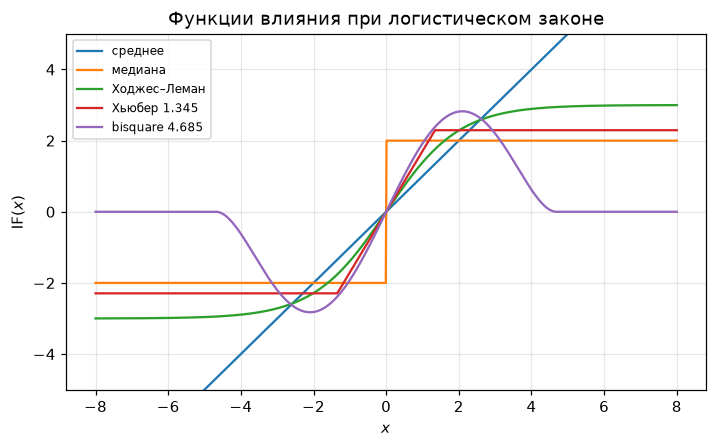

In [3]:
INT_F2 = LOGIS.expect(LOGIS.pdf)
PSI1 = {"Хьюбер 1.345": Huber(1.345), "bisquare 4.685": Bisquare(4.685)}

ESTIMATORS1 = {
    "среднее": lambda x: x.mean(axis=-1),
    "медиана": median,
    "Ходжес–Леман": hodges_lehmann,
} | {name: (lambda x, psi=psi: m_location(x, psi)) for name, psi in PSI1.items()}

IF1 = {
    "среднее": lambda u: u,
    "медиана": lambda u: np.sign(u) / (2 * LOGIS.pdf(0.0)),
    "Ходжес–Леман": lambda u: (LOGIS.cdf(u) - 0.5) / INT_F2,
} | {name: (lambda u, psi=psi, d=LOGIS.expect(psi.dpsi, psi.points): psi.psi(u) / d) for name, psi in PSI1.items()}

_g = np.linspace(-20, 20, 4001)
assert np.allclose(IF1["Ходжес–Леман"](_g), 3 * np.tanh(_g / 2), atol=1e-12)

_u = np.linspace(-8, 8, 1601)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, fn in IF1.items():
    ax.plot(_u, fn(_u), label=name)
ax.set_ylim(-5, 5)
ax.set_xlabel("$x$")
ax.set_ylabel(r"$\mathrm{IF}(x)$")
ax.set_title("Функции влияния при логистическом законе")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Функция влияния среднего не ограничена: одно наблюдение может сдвинуть оценку сколь угодно далеко. У медианы, оценки Ходжеса–Лемана и оценки Хьюбера IF ограничена и монотонна: влияние далёкого наблюдения ограничено, но не исчезает. У bisquare IF обращается в ноль при $\lvert x\rvert > c$: далёкие наблюдения на оценку не влияют.

### 1.3. Gross-error sensitivity

$$\gamma^* = \sup_x\lvert\mathrm{IF}(x; T, F)\rvert:$$

- среднее: $\gamma^* = \infty$;
- медиана: $\gamma^* = 1/(2f(0)) = 2$;
- Ходжес–Леман: $\gamma^* = \lim_{x\to\infty}3\operatorname{th}(x/2) = 3$;
- Хьюбер: $\gamma^* = k/(2F(k) - 1)$;
- bisquare: $\lvert\psi_c\rvert$ максимальна при $u = c/\sqrt5$, откуда $\gamma^* = \dfrac{16c}{25\sqrt5\,\mathbb E\psi_c'(U)}$.

In [4]:
GES1 = {
    "среднее": np.inf,
    "медиана": 1 / (2 * LOGIS.pdf(0.0)),
    "Ходжес–Леман": 0.5 / INT_F2,
} | {name: ges(psi, LOGIS) for name, psi in PSI1.items()}

_wide = np.linspace(-60, 60, 1_200_001)
assert all(abs(np.max(np.abs(IF1[name](_wide))) - g) < 1e-6 for name, g in GES1.items() if np.isfinite(g))
pd.Series(GES1, name="γ*").to_frame()

,γ*
среднее,inf
медиана,2.0000
Ходжес–Леман,3.0000
Хьюбер 1.345,2.2928
bisquare 4.685,2.8250


Наименьшая чувствительность к грубым ошибкам у медианы, наибольшая среди ограниченных оценок — у оценки Ходжеса–Лемана. У bisquare $\gamma^*$ больше, чем у Хьюбера: константа $c = 4.685$ подобрана для нормального закона, а у логистического закона заметная доля наблюдений попадает на убывающий участок $\psi_c$, и знаменатель $\mathbb E\psi_c'(U)$ мал.

### 1.4. Асимптотическая дисперсия

Для достаточно гладкого функционала $T(F_n) = T(F) + \frac1n\sum_i\mathrm{IF}(X_i; T, F) + o_P(n^{-1/2})$ и $\mathbb E_F\,\mathrm{IF} = 0$, откуда
$$\sqrt n\bigl(T(F_n) - T(F)\bigr) \Rightarrow N(0, v^2),\qquad v^2 = \mathbb E_F\,\mathrm{IF}^2(X; T, F).$$
Для M-оценок это формула $\mathbb E\psi^2/(\mathbb E\psi')^2$ из лабораторной работы №1. Проверка: для $n \in \{50, 200, 1000\}$ генерируется по $R = 5000$ выборок, $n\,\widehat{\operatorname{Var}}(T_n)$ сравнивается с $\mathbb E_F\,\mathrm{IF}^2$, вычисленным интегрированием.

In [5]:
V2 = {name: LOGIS.expect(lambda u, fn=fn: fn(u) ** 2, getattr(PSI1.get(name), "points", ())) for name, fn in IF1.items()}

_rng = rng_for(1)
_rows = []
for n in NS:
    X = MU + LOGIS.rvs((R, n), _rng)
    for name, est in ESTIMATORS1.items():
        _rows.append({"n": n, "оценка": name, "n·Var": n * est(X).var(ddof=1)})
if_mc = pd.DataFrame(_rows).pivot(index="оценка", columns="n", values="n·Var").loc[list(ESTIMATORS1)]
assert (abs(if_mc[NS[-1]] / pd.Series(V2) - 1) < MC_TOL).all()
if_mc.columns = [f"n·Var, n={n}" for n in if_mc.columns]
if_mc["E IF²"] = pd.Series(V2)
if_mc

,"n·Var, n=50","n·Var, n=200","n·Var, n=1000",E IF²
оценка,,,,
среднее,3.3320,3.2882,3.3668,3.2899
медиана,3.9364,3.9313,4.2116,4.0000
Ходжес–Леман,3.0867,2.9911,3.0812,3.0000
Хьюбер 1.345,3.1538,3.0716,3.1809,3.0891
bisquare 4.685,3.6688,3.5593,3.6951,3.5665


При $n = 200$ выборочные $n\,\widehat{\operatorname{Var}}(T_n)$ отличаются от $\mathbb E_F\,\mathrm{IF}^2$ не больше чем на 1.7%, при $n = 1000$ — в пределах погрешности моделирования (порог $3\sqrt{2/(R-1)} \approx 6\%$). Отклонения при $n = 1000$ одного знака, потому что все оценки вычисляются по одним и тем же выборкам. Равенство $v^2 = \mathbb E_F\,\mathrm{IF}^2$ подтверждается для всех пяти оценок.

## Задание 2. Информативность оценки и точка срыва

### 2.1. Оценка Ходжеса–Лемана и её точка срыва

Точка срыва — наибольшая доля засорения, при которой оценку нельзя увести в бесконечность: $\varepsilon^* = \sup\bigl\{\varepsilon:\ \sup_G\lvert T((1-\varepsilon)F + \varepsilon G)\rvert < \infty\bigr\}$. Конечновыборочная точка срыва $\varepsilon_n^*$ — наименьшая доля $m/n$ наблюдений, заменой которых оценку можно сделать сколь угодно большой.

Если доля $\varepsilon$ наблюдений уходит в $+\infty$, туда же уходят все средние Уолша, содержащие хотя бы одно такое наблюдение, — асимптотически доля $1 - (1-\varepsilon)^2$. Медиана средних Уолша ограничена, пока конечных средних больше половины:
$$(1-\varepsilon)^2 > \frac12,\qquad \varepsilon^* = 1 - \frac1{\sqrt2} \approx 0.293.$$
При конечном $n$ конечны $K_m = (n-m)(n-m+1)/2$ из $N = n(n+1)/2$ средних Уолша, и оценка ограничена, пока $K_m \ge \lfloor N/2\rfloor + 1$. Модель — логистическая, как в задании 1, $n = 100$.

In [6]:
N2 = 100
BP_HL = 1 - 1 / np.sqrt(2)


def bp_n_hl(n):
    need = n * (n + 1) // 2 // 2 + 1
    return next(m for m in range(n + 1) if (n - m) * (n - m + 1) // 2 < need) / n


def bp_n_empirical(est, x, far=1e12):
    for m in range(len(x) + 1):
        y = x.copy()
        y[:m] = far
        if abs(est(y)) > 1e6:
            return m / len(x)


BP_N = bp_n_hl(N2)
_bp_emp = bp_n_empirical(hodges_lehmann, LOGIS.rvs(N2, rng_for(20)))
assert _bp_emp == BP_N
pd.Series({"ε*": BP_HL, f"ε*_n по формуле, n = {N2}": BP_N, "ε*_n, эксперимент": _bp_emp}, name="Ходжес–Леман").to_frame()

,Ходжес–Леман
ε*,0.2929
"ε*_n по формуле, n = 100",0.3000
"ε*_n, эксперимент",0.3000


### 2.2. Информативность

Ниже точки срыва смещение оценки ограничено при любых значениях выбросов, и по её значению параметр восстанавливается с точностью до этого смещения. Начиная с точки срыва значение оценки определяют выбросы, и о $\mu$ она ничего не сообщает. Это проверяется двумя экспериментами: смещение в зависимости от удалённости выбросов и доля дисперсии оценки, объясняемая параметром.

### 2.3. Смещение и удалённость выбросов

В 500 выборках объёма $n = 100$ первые $m$ наблюдений заменяются на $\mu + d$, $d \in [1, 10^4]$; значения $m$ выбраны вокруг $n\varepsilon^*_n = 30$.

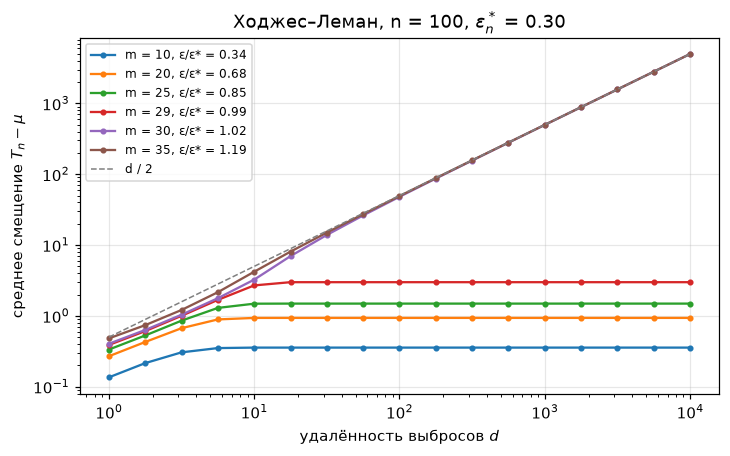

,10,20,25,29,30,35
d,,,,,,
1.0000,0.1353,0.2689,0.3342,0.3882,0.4033,0.4805
10.0000,0.3561,0.9351,1.4853,2.6914,3.2457,4.1989
100.0000,0.3561,0.9356,1.4894,2.9887,48.0826,49.1859
10000.0000,0.3561,0.9356,1.4894,2.9887,4998.0826,4999.1859


In [7]:
M_LIST = (10, 20, 25, 29, 30, 35)
D_GRID = np.logspace(0, 4, 17)
_X0 = MU + LOGIS.rvs((500, N2), rng_for(21))
_bias = {}
for m in M_LIST:
    for d in D_GRID:
        X = _X0.copy()
        X[:, :m] = MU + d
        _bias[(m, d)] = hodges_lehmann(X).mean() - MU
bias_d = pd.Series(_bias).unstack(0)
assert (bias_d.loc[:, [m for m in M_LIST if m / N2 < BP_N]].iloc[-1] < 10).all()
assert (bias_d.loc[:, [m for m in M_LIST if m / N2 >= BP_N]].iloc[-1] > 1000).all()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in M_LIST:
    ax.loglog(D_GRID, bias_d[m], marker="o", ms=3, label=f"m = {m}, ε/ε* = {m / N2 / BP_HL:.2f}")
ax.loglog(D_GRID, D_GRID / 2, color="gray", ls="--", lw=1, label="d / 2")
ax.set_xlabel("удалённость выбросов $d$")
ax.set_ylabel(r"среднее смещение $T_n - \mu$")
ax.set_title(f"Ходжес–Леман, n = {N2}, $\\varepsilon^*_n$ = {BP_N:.2f}")
ax.legend(fontsize=8)
plt.show()
bias_d.iloc[[0, 4, 8, 16]].rename_axis("d")

Пока $m \le 29$ ($\varepsilon < \varepsilon^*_n$), смещение перестаёт зависеть от $d$ уже при $d \approx 10$–$100$: далёкие выбросы влияют на оценку своим количеством, но не значением. Уровень плато быстро растёт при приближении к точке срыва: 0.36 при $m = 10$ — вдвое больше стандартной ошибки $\sqrt{3/100} \approx 0.17$, — и 2.99 при $m = 29$, в 17 раз больше. При $m \ge 30$ смещение растёт вместе с $d$ (как $d/2$ минус константа): медиана средних Уолша попадает в средние вида $(x_i + \mu + d)/2$.

### 2.4. Доля дисперсии, объясняемая параметром

В 2000 выборках объёма $n = 100$ параметр случаен, $\mu_r \sim U(-5, 5)$, а первые $m$ наблюдений заменяются на одно и то же значение $A_r$, $\lg A_r \sim U(2, 4)$, не связанное с $\mu$. Для $m = 0, \dots, 45$ вычисляется $\rho^2 = \operatorname{corr}^2(T_n, \mu)$: $\rho^2 \approx 1$ — оценка следует за параметром, $\rho^2 \approx 0$ — её значение определяют выбросы.

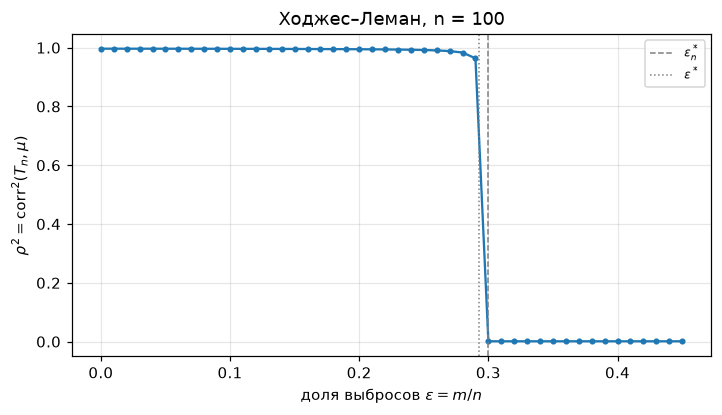

,ρ²
m,
0,0.9965
10,0.9961
20,0.9946
25,0.9920
29,0.9637
30,0.0011
35,0.0011


In [8]:
_rng = rng_for(25)
R2 = 2000
_mu = _rng.uniform(-5, 5, R2)
_A = 10 ** _rng.uniform(2, 4, R2)
_U = LOGIS.rvs((R2, N2), _rng)
_rho2 = {}
for m in range(46):
    X = _mu[:, None] + _U
    X[:, :m] = _A[:, None]
    _rho2[m] = np.corrcoef(hodges_lehmann(X), _mu)[0, 1] ** 2
rho2 = pd.Series(_rho2)
M_STAR = int(round(BP_N * N2))
assert rho2.loc[: M_STAR - 1].min() > 0.9 and rho2.loc[M_STAR:].max() < 0.05

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(rho2.index / N2, rho2.values, marker="o", ms=3)
ax.axvline(BP_N, color="gray", ls="--", lw=1, label=r"$\varepsilon^*_n$")
ax.axvline(BP_HL, color="gray", ls=":", lw=1, label=r"$\varepsilon^*$")
ax.set_xlabel(r"доля выбросов $\varepsilon = m/n$")
ax.set_ylabel(r"$\rho^2 = \mathrm{corr}^2(T_n, \mu)$")
ax.set_title(f"Ходжес–Леман, n = {N2}")
ax.legend(fontsize=8)
plt.show()
rho2.loc[[0, 10, 20, 25, 29, 30, 35]].to_frame("ρ²").rename_axis("m")

Пока $m < 30$, $\rho^2 > 0.96$: оценка следует за параметром, хотя её смещение уже велико (п. 2.3). При $m = 30 = n\varepsilon^*_n$ доля объяснённой дисперсии скачком падает почти до нуля: значение оценки задают выбросы. Величина $\rho^2$ за точкой срыва зависит от устройства эксперимента (положение выбросов случайно), устойчив сам скачок.

Итог задания 2: ниже точки срыва оценка информативна, но с точностью до смещения, которое быстро растёт по мере приближения к $\varepsilon^*$; начиная с $\varepsilon^*_n$ оценка информативность теряет.

## Задание 3. M-оценки сдвига нормального закона с масштабом MAD

### 3.1. Модель

$X_i = \mu + \sigma Z_i$, $Z_i \sim N(0, 1)$. Масштаб оценивается заранее, $\hat\sigma = \mathrm{MADN}$ (состоятельна при нормальном законе, точка срыва 0.5), затем $\hat\mu$ — корень уравнения $\sum_i\psi\bigl((x_i - \mu)/\hat\sigma\bigr) = 0$. В моделировании $\mu = 3$, $\sigma = 2$.

Дифференцируя уравнение $\mathbb E_F\psi\bigl((X - T)/S\bigr) = 0$ при засорении $F_t = (1-t)\Phi_{\mu,\sigma} + t\delta_x$, получаем
$$\mathrm{IF}_T(x) = \sigma\,\frac{\psi(z) - \mathbb E\psi'(Z)Z\cdot\mathrm{IF}_S(x)/\sigma}{\mathbb E\psi'(Z)},\qquad z = \frac{x - \mu}\sigma.$$
При нечётной $\psi$ и симметричном законе $\mathbb E\psi'(Z)Z = 0$ (лабораторная работа №1, п. 3), поэтому $\mathrm{IF}_T = \sigma\psi(z)/\mathbb E\psi'(Z)$ и $v^2 = \sigma^2\,\mathbb E\psi^2/(\mathbb E\psi')^2$ — как при известной $\sigma$.

### 3.2. Константы по эффективности

Асимптотическая эффективность $\mathrm{eff}(\psi) = (\mathbb E\psi'(Z))^2/\mathbb E\psi^2(Z)$ монотонно растёт по константе, и уравнения $\mathrm{eff}(k) = \Delta$, $\mathrm{eff}(c) = \Delta$ при $\Delta = 0.95$ решаются методом Брента. Проверка моделированием: $n\,\widehat{\operatorname{Var}}(\hat\mu)/\sigma^2$ при $\hat\sigma = \mathrm{MADN}$ сравнивается с $1/\Delta$.

In [9]:
DELTA = 0.95
SIGMA = 2.0


def tune(cls, lo, hi):
    return optimize.brentq(lambda a: 1 / av_location(cls(a), NORM) - DELTA, lo, hi, xtol=1e-12)


K_D, C_D = tune(Huber, 0.1, 5.0), tune(Bisquare, 1.0, 15.0)
PSI3 = {"Хьюбер": Huber(K_D), "bisquare": Bisquare(C_D)}
assert abs(K_D - 1.345) < 1e-3 and abs(C_D - 4.685) < 1e-3

_rng = rng_for(31)
_rows = []
for n in NS:
    X = MU + SIGMA * NORM.rvs((R, n), _rng)
    s = madn(X)
    for name, psi in PSI3.items():
        _rows.append({"n": n, "ψ": name, "n·Var/σ²": n * m_location(X, psi, s).var(ddof=1) / SIGMA**2})
eff_mc = pd.DataFrame(_rows).pivot(index="ψ", columns="n", values="n·Var/σ²").loc[list(PSI3)]
assert (abs(eff_mc[NS[-1]] * DELTA - 1) < MC_TOL).all()
eff_mc.columns = [f"n·Var/σ², n={n}" for n in eff_mc.columns]
eff_mc.insert(0, "константа", [K_D, C_D])
eff_mc["1/Δ"] = 1 / DELTA
eff_mc

,константа,"n·Var/σ², n=50","n·Var/σ², n=200","n·Var/σ², n=1000",1/Δ
ψ,,,,,
Хьюбер,1.3450,1.0708,1.0622,1.0460,1.0526
bisquare,4.6851,1.0795,1.0639,1.0473,1.0526


Получены $k = 1.3450$ и $c = 4.6851$ — стандартные константы, использованные в лабораторной работе №1. При $n = 1000$ моделирование с $\hat\sigma = \mathrm{MADN}$ даёт эффективность 0.955–0.956: подстановка MAD асимптотическую дисперсию не меняет.

### 3.3. Gross-error sensitivity и максимальное смещение

$$\gamma^* = \sup_x\lvert\mathrm{IF}_T(x)\rvert = \sigma\,\frac{\sup\lvert\psi\rvert}{\mathbb E\psi'(Z)}:\qquad \gamma^*_{\mathrm H} = \frac{\sigma k}{2\Phi(k) - 1},\qquad \gamma^*_{\mathrm B} = \sigma\,\frac{16c}{25\sqrt5\,\mathbb E\psi_c'(Z)}.$$
Подсказку задания понимаем как соотношение $B(\varepsilon)/\varepsilon \to \gamma^*$ при $\varepsilon \to 0$: по определению функции влияния выброс в точке $x$ сдвигает оценку на $\varepsilon\,\mathrm{IF}(x) + o(\varepsilon)$, и наибольший сдвиг даёт точка с максимальным $\lvert\mathrm{IF}\rvert$. Поэтому максимальное смещение при доле выбросов $\varepsilon$ приближённо равно $B(\varepsilon) \approx \varepsilon\gamma^*$. Эмпирически оно оценивается в п. 3.4.

In [10]:
GES3 = {name: ges(psi, NORM) for name, psi in PSI3.items()}
pd.DataFrame({"γ*/σ": GES3} | {f"εγ*/σ, ε = {e}": {name: e * g for name, g in GES3.items()} for e in (0.05, 0.1, 0.2)})

,γ*/σ,"εγ*/σ, ε = 0.05","εγ*/σ, ε = 0.1","εγ*/σ, ε = 0.2"
Хьюбер,1.6375,0.0819,0.1637,0.3275
bisquare,1.7696,0.0885,0.1770,0.3539


### 3.4. Асимптотическое смещение в зависимости от точки загрязнения

Доля выбросов $\varepsilon = 0.1$, выбросы — вырожденное распределение: в каждой выборке ровно $\varepsilon n$ наблюдений равны $\mu + \sigma x_0$, остальные взяты из $N(\mu, \sigma^2)$. Смещение $(\hat\mu - \mu)/\sigma$ оценивается как среднее по 200 выборкам разности оценок по засорённой и исходной выборке (это убирает общий случайный шум) при $n = 500$ и $n = 2000$; совпадение двух кривых означает, что найдено асимптотическое смещение. Сетка $x_0 \in [0, 8]$ с шагом 0.25; при $x_0 < 0$ смещение меняет знак. Пунктиром показано линейное приближение $\varepsilon\,\mathrm{IF}(x_0)$, точечной горизонталью — $\varepsilon\gamma^*$.

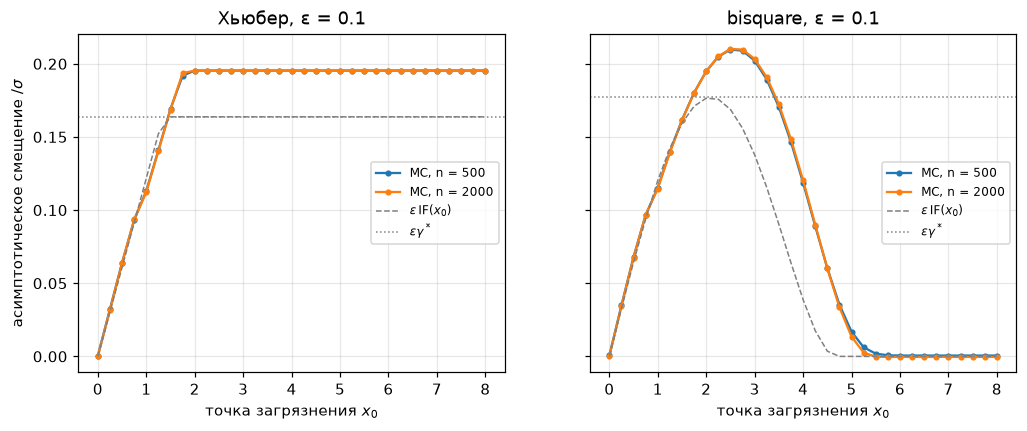

,max смещение (MC),εγ*,отношение
Хьюбер,0.1953,0.1637,1.1928
bisquare,0.2102,0.1770,1.1877


In [11]:
EPS_B = 0.1
X0_GRID = np.arange(0.0, 8.01, 0.25)
N_B, R_B = (500, 2000), 200
_rng = rng_for(34)
_rows = []
for n in N_B:
    clean = MU + SIGMA * NORM.rvs((R_B, n), _rng)
    base = {name: m_location(clean, psi, madn(clean)) for name, psi in PSI3.items()}
    m = int(EPS_B * n)
    for x0 in X0_GRID:
        X = clean.copy()
        X[:, :m] = MU + SIGMA * x0
        s = madn(X)
        for name, psi in PSI3.items():
            diff = (m_location(X, psi, s) - base[name]) / SIGMA
            _rows.append({"n": n, "ψ": name, "x₀": x0, "смещение": diff.mean()})
bias_mc = pd.DataFrame(_rows).pivot(index="x₀", columns=["ψ", "n"], values="смещение")
assert all((abs(bias_mc[name][N_B[0]] - bias_mc[name][N_B[1]]) < 0.005).all() for name in PSI3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, psi) in zip(axes, PSI3.items()):
    for n in N_B:
        ax.plot(X0_GRID, bias_mc[name][n], marker="o", ms=3, label=f"MC, n = {n}")
    _if = psi.psi(X0_GRID) / NORM.expect(psi.dpsi, psi.points)
    ax.plot(X0_GRID, EPS_B * _if, color="gray", ls="--", lw=1, label=r"$\varepsilon\,\mathrm{IF}(x_0)$")
    ax.axhline(EPS_B * GES3[name], color="gray", ls=":", lw=1, label=r"$\varepsilon\gamma^*$")
    ax.set_title(f"{name}, ε = {EPS_B}")
    ax.set_xlabel("точка загрязнения $x_0$")
    ax.legend(fontsize=8, loc="center right")
axes[0].set_ylabel(r"асимптотическое смещение $/\sigma$")
plt.show()

_last = bias_mc.xs(N_B[-1], axis=1, level="n")
_lin = pd.Series({name: EPS_B * g for name, g in GES3.items()})
pd.DataFrame({"max смещение (MC)": _last.max(), "εγ*": _lin, "отношение": _last.max() / _lin}).loc[list(PSI3)]

Кривые при $n = 500$ и $n = 2000$ совпадают (расхождение не больше 0.004), т.е. найдено асимптотическое смещение. У оценки Хьюбера смещение растёт, пока выброс в зоне линейности $\psi$, и при $x_0 \gtrsim 2$ выходит на плато $0.195\sigma$: дальше положение выброса не важно. У bisquare смещение максимально ($0.210\sigma$ при $x_0 \approx 2.5$), а при $x_0 \gtrsim 5.5$ равно нулю: такие выбросы получают нулевой вес. Граница больше $c = 4.685$, потому что выбросы увеличивают MAD и отбрасываются наблюдения дальше $c\hat\sigma > c\sigma$.

Максимум кривой — эмпирическая оценка максимального смещения из п. 3.3: $0.195\sigma$ у Хьюбера и $0.210\sigma$ у bisquare против $\varepsilon\gamma^* = 0.164\sigma$ и $0.177\sigma$. Линейное приближение передаёт форму кривых, но при $\varepsilon = 0.1$ занижает максимальное смещение примерно на 20%: оно не учитывает нелинейность функционала и смещение самой оценки масштаба при засорении.

### 3.5. Распределение Коши

Теперь $X_i = \mu + \sigma U_i$, $U_i \sim C(0, 1)$, процедура прежняя: $\hat\sigma = \mathrm{MADN}$, константы $k$ и $c$ из п. 3.2. Для закона Коши $F^{-1}(3/4) = 1$, поэтому, как в лабораторной работе №1 (п. 2), $\mathrm{MAD} \to \sigma$, а $\mathrm{MADN} \to \theta\sigma$, $\theta = 1/0.6745 \approx 1.483$. Случайная ошибка $\hat\sigma$ на асимптотику $\hat\mu$ не влияет (п. 3.1), важен только предел $\theta\sigma$:
$$\frac{v^2}{\sigma^2} = \theta^2\,\frac{\mathbb E\psi^2(U/\theta)}{\bigl(\mathbb E\psi'(U/\theta)\bigr)^2},$$
т.е. это M-оценка с известным масштабом и константой $k\theta$ ($c\theta$). Основной вариант — MADN, как в п. 3.1; для сравнения приведён масштаб MAD без нормировки ($\theta = 1$), состоятельный для закона Коши. Ориентиры: медиана, $v^2 = \pi^2\sigma^2/4 \approx 2.47\sigma^2$, и нижняя граница Рао–Крамера $2\sigma^2$.

In [12]:
THETA_C = 1 / Q75
AV_C = pd.DataFrame({
    "MADN": {name: av_location(psi, CAUCHY, THETA_C) for name, psi in PSI3.items()},
    "MAD": {name: av_location(psi, CAUCHY, 1.0) for name, psi in PSI3.items()},
})

_rng = rng_for(35)
_rows = []
for n in NS:
    X = MU + SIGMA * CAUCHY.rvs((R, n), _rng)
    s = madn(X)
    for name, psi in PSI3.items():
        for scale, sc in (("MADN", s), ("MAD", s * Q75)):
            mu_hat = m_location(X, psi, sc)
            _rows.append({"n": n, "ψ": name, "масштаб": scale, "n·Var/σ²": n * mu_hat.var(ddof=1) / SIGMA**2})
cauchy_mc = pd.DataFrame(_rows).pivot(index=["ψ", "масштаб"], columns="n", values="n·Var/σ²")
cauchy_mc = cauchy_mc.loc[[(name, scale) for name in PSI3 for scale in AV_C.columns]]
_theory = pd.Series({idx: AV_C.loc[idx[0], idx[1]] for idx in cauchy_mc.index})
assert (abs(cauchy_mc[NS[-1]].values / _theory.values - 1) < MC_TOL).all()
cauchy_mc.columns = [f"n·Var/σ², n={n}" for n in cauchy_mc.columns]
cauchy_mc["v²/σ² (теория)"] = _theory.values
cauchy_mc

n·Var/σ², n=50  n·Var/σ², n=200  n·Var/σ², n=1000  v²/σ² (теория)
ψ        масштаб                                                                   
Хьюбер   MADN             3.8281           3.4254            3.4978          3.5142
         MAD              3.0919           2.7719            2.8453          2.8425
bisquare MADN             3.1217           2.7538            2.8177          2.7898
         MAD              2.5621           2.3596            2.3932          2.3503

Теоретические дисперсии подтверждаются моделированием при $n = 1000$ для обоих вариантов масштаба. С константами из п. 3.2 и масштабом MADN оценка Хьюбера имеет $v^2 \approx 3.51\sigma^2$ — больше, чем у медианы ($2.47\sigma^2$); у bisquare $v^2 \approx 2.79\sigma^2$. Константы подобраны для нормального закона, а MADN ещё увеличивает их в $\theta \approx 1.48$ раза. Сильнее страдает монотонная функция Хьюбера: далёкие наблюдения сохраняют вклад $(k\theta)^2$ в $\mathbb E\psi^2$, тогда как bisquare их отбрасывает. С масштабом MAD ($\theta = 1$) дисперсии меньше: $2.84\sigma^2$ и $2.35\sigma^2$.

## Выводы

1. Для модели сдвига логистического закона получены функции влияния пяти оценок. Не ограничена только IF среднего ($\gamma^* = \infty$); у медианы $\gamma^* = 2$, у оценки Ходжеса–Лемана 3, у Хьюбера 2.29, у bisquare 2.83, и только у bisquare IF обращается в ноль вдали от центра. Моделирование подтвердило $v^2 = \mathbb E_F\,\mathrm{IF}^2$ для всех оценок.
2. Точка срыва оценки Ходжеса–Лемана $1 - 1/\sqrt2 \approx 0.293$ (0.30 при $n = 100$). Ниже неё смещение ограничено по удалённости выбросов и оценка следует за параметром ($\rho^2 > 0.96$), но смещение быстро растёт по мере приближения к точке срыва. При доле выбросов $\varepsilon^*_n$ оценка скачком теряет информативность ($\rho^2 \approx 0.001$).
3. Эффективность 95% при нормальном законе дают $k = 1.3450$ и $c = 4.6851$; подстановка MAD асимптотическую дисперсию не меняет. $\gamma^* = 1.64\sigma$ (Хьюбер) и $1.77\sigma$ (bisquare). При $\varepsilon = 0.1$ максимальное смещение по эксперименту $0.195\sigma$ и $0.210\sigma$ — примерно на 20% больше линейного приближения $\varepsilon\gamma^*$. Далёкие выбросы смещают оценку Хьюбера на постоянную величину, а на bisquare не влияют.
4. При законе Коши с теми же константами и масштабом MADN $v^2 \approx 3.51\sigma^2$ (Хьюбер) и $2.79\sigma^2$ (bisquare), с MAD — $2.84\sigma^2$ и $2.35\sigma^2$; моделирование это подтверждает. Константы, подобранные под нормальный закон, для закона Коши велики, и оценка Хьюбера уступает даже медиане.